# Analisis de delincuencia


## Importacion de librerias

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Importacion del dataset
Debido al peso del archivo, no se sube a GitHub, cada una lo deja descomprimido en la carpeta del proyecto.

In [13]:
df = pd.read_csv("datos_sobre_delincuencia.csv")
df.head()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
0,211507896,2021 Apr 11 12:00:00 AM,2020 Nov 07 12:00:00 AM,845,15,N Hollywood,1502,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,7800 BEEMAN AV,NaN,34.2124,-118.4092
1,201516622,2020 Oct 21 12:00:00 AM,2020 Oct 18 12:00:00 AM,1845,15,N Hollywood,1521,1,230,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",...,IC,Invest Cont,230.0,NaN,NaN,NaN,ATOLL AV,N GAULT,34.1993,-118.4203
2,240913563,2024 Dec 10 12:00:00 AM,2020 Oct 30 12:00:00 AM,1240,9,Van Nuys,933,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,14600 SYLVAN ST,NaN,34.1847,-118.4509
3,210704711,2020 Dec 24 12:00:00 AM,2020 Dec 24 12:00:00 AM,1310,7,Wilshire,782,1,331,THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND ...,...,IC,Invest Cont,331.0,NaN,NaN,NaN,6000 COMEY AV,NaN,34.0339,-118.3747
4,201418201,2020 Oct 03 12:00:00 AM,2020 Sep 29 12:00:00 AM,1830,14,Pacific,1454,1,420,THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER),...,IC,Invest Cont,420.0,NaN,NaN,NaN,4700 LA VILLA MARINA,NaN,33.9813,-118.4350


## Exploracion inicial

In [14]:
df.shape

(1004894, 28)

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1004894 entries, 0 to 1004893
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DR_NO           1004894 non-null  int64  
 1   Date Rptd       1004894 non-null  str    
 2   DATE OCC        1004894 non-null  str    
 3   TIME OCC        1004894 non-null  int64  
 4   AREA            1004894 non-null  int64  
 5   AREA NAME       1004894 non-null  str    
 6   Rpt Dist No     1004894 non-null  int64  
 7   Part 1-2        1004894 non-null  int64  
 8   Crm Cd          1004894 non-null  int64  
 9   Crm Cd Desc     1004894 non-null  str    
 10  Mocodes         853296 non-null   str    
 11  Vict Age        1004894 non-null  int64  
 12  Vict Sex        860263 non-null   str    
 13  Vict Descent    860251 non-null   str    
 14  Premis Cd       1004878 non-null  float64
 15  Premis Desc     1004306 non-null  str    
 16  Weapon Used Cd  327216 non-null   float64
 17  

In [16]:
df.describe(include="all")

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
count,1.004894e+06,1004894,1004894,1.004894e+06,1.004894e+06,1004894,1.004894e+06,1.004894e+06,1.004894e+06,1004894,...,1004893,1004894,1.004883e+06,69154.000000,2314.000000,64.00000,1004894,154228,1.004894e+06,1.004894e+06
unique,NaN,1870,1826,NaN,NaN,21,NaN,NaN,NaN,140,...,6,6,NaN,NaN,NaN,NaN,66566,10413,NaN,NaN
top,NaN,2023 Feb 02 12:00:00 AM,2020 Jan 01 12:00:00 AM,NaN,NaN,Central,NaN,NaN,NaN,VEHICLE - STOLEN,...,IC,Invest Cont,NaN,NaN,NaN,NaN,800 N ALAMEDA ST,BROADWAY,NaN,NaN
freq,NaN,929,1164,NaN,NaN,69668,NaN,NaN,NaN,115184,...,802772,802772,NaN,NaN,NaN,NaN,2598,2486,NaN,NaN
mean,2.202190e+08,NaN,NaN,1.339901e+03,1.069153e+01,NaN,1.115613e+03,1.400313e+00,5.001386e+02,NaN,...,NaN,NaN,4.998992e+02,958.097796,984.015990,991.21875,NaN,NaN,3.399820e+01,-1.180908e+02
std,1.319070e+07,NaN,NaN,6.510761e+02,6.110248e+00,NaN,6.111596e+02,4.899620e-01,2.052638e+02,NaN,...,NaN,NaN,2.050643e+02,110.358509,52.350982,27.06985,NaN,NaN,1.610789e+00,5.582654e+00
min,8.170000e+02,NaN,NaN,1.000000e+00,1.000000e+00,NaN,1.010000e+02,1.000000e+00,1.100000e+02,NaN,...,NaN,NaN,1.100000e+02,210.000000,310.000000,821.00000,NaN,NaN,0.000000e+00,-1.186676e+02
25%,2.106168e+08,NaN,NaN,9.000000e+02,5.000000e+00,NaN,5.870000e+02,1.000000e+00,3.310000e+02,NaN,...,NaN,NaN,3.310000e+02,998.000000,998.000000,998.00000,NaN,NaN,3.401470e+01,-1.184305e+02
50%,2.209158e+08,NaN,NaN,1.420000e+03,1.100000e+01,NaN,1.139000e+03,1.000000e+00,4.420000e+02,NaN,...,NaN,NaN,4.420000e+02,998.000000,998.000000,998.00000,NaN,NaN,3.405890e+01,-1.183225e+02
75%,2.311102e+08,NaN,NaN,1.900000e+03,1.600000e+01,NaN,1.613000e+03,2.000000e+00,6.260000e+02,NaN,...,NaN,NaN,6.260000e+02,998.000000,998.000000,998.00000,NaN,NaN,3.416490e+01,-1.182739e+02


In [17]:
df.isna().sum().sort_values(ascending=False)

Crm Cd 4          1004830
Crm Cd 3          1002580
Crm Cd 2           935740
Cross Street       850666
Weapon Used Cd     677678
Weapon Desc        677678
Mocodes            151598
Vict Descent       144643
Vict Sex           144631
Premis Desc           588
Premis Cd              16
Crm Cd 1               11
Status                  1
Vict Age                0
Crm Cd                  0
Crm Cd Desc             0
AREA NAME               0
Rpt Dist No             0
AREA                    0
TIME OCC                0
Date Rptd               0
DATE OCC                0
DR_NO                   0
Part 1-2                0
Status Desc             0
LOCATION                0
LAT                     0
LON                     0
dtype: int64

## Delitos mas frecuentes

In [18]:
top_delitos = df["Crm Cd Desc"].value_counts().head(15)
top_delitos

Crm Cd Desc
VEHICLE - STOLEN                                            115184
BATTERY - SIMPLE ASSAULT                                     74821
BURGLARY FROM VEHICLE                                        63515
THEFT OF IDENTITY                                            62536
VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)      61086
BURGLARY                                                     57871
THEFT PLAIN - PETTY ($950 & UNDER)                           53716
ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT               53523
INTIMATE PARTNER - SIMPLE ASSAULT                            46712
THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER)              41311
THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND OVER)          36940
THEFT-GRAND ($950.01 & OVER)EXCPT,GUNS,FOWL,LIVESTK,PROD     35149
ROBBERY                                                      32315
SHOPLIFTING - PETTY THEFT ($950 & UNDER)                     30908
VANDALISM - MISDEAMEANOR ($399 OR UNDER)          

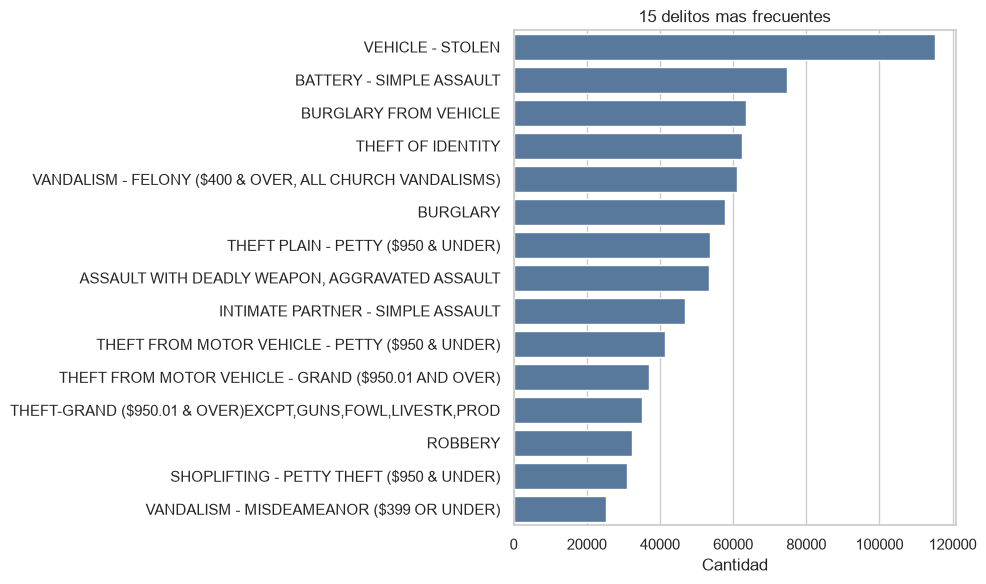

In [19]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_delitos.values, y=top_delitos.index, color="#4C78A8")
plt.title("15 delitos mas frecuentes")
plt.xlabel("Cantidad")
plt.ylabel("")
plt.tight_layout()
plt.show()

## Por area y sexo de la victima

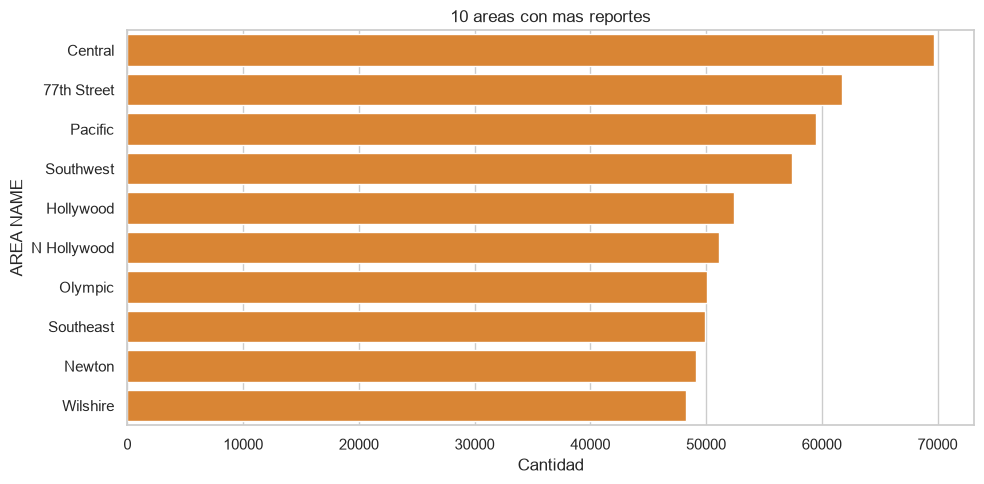

In [20]:
top_areas = df["AREA NAME"].value_counts().head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_areas.values, y=top_areas.index, color="#F58518")
plt.title("10 areas con mas reportes")
plt.xlabel("Cantidad")
plt.tight_layout()
plt.show()

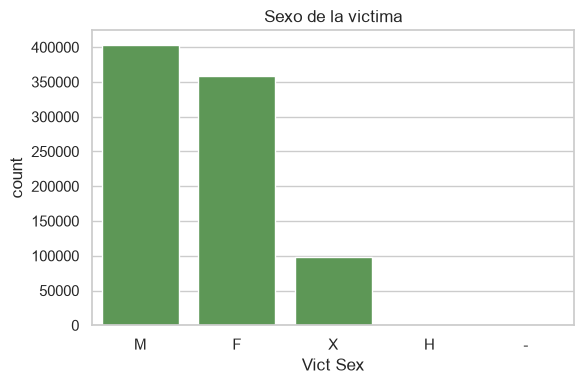

In [21]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Vict Sex", order=df["Vict Sex"].value_counts().index, color="#54A24B")
plt.title("Sexo de la victima")
plt.tight_layout()
plt.show()

In [22]:
df.isnull().sum()

DR_NO                   0
Date Rptd               0
DATE OCC                0
TIME OCC                0
AREA                    0
AREA NAME               0
Rpt Dist No             0
Part 1-2                0
Crm Cd                  0
Crm Cd Desc             0
Mocodes            151598
Vict Age                0
Vict Sex           144631
Vict Descent       144643
Premis Cd              16
Premis Desc           588
Weapon Used Cd     677678
Weapon Desc        677678
Status                  1
Status Desc             0
Crm Cd 1               11
Crm Cd 2           935740
Crm Cd 3          1002580
Crm Cd 4          1004830
LOCATION                0
Cross Street       850666
LAT                     0
LON                     0
dtype: int64

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1004894 entries, 0 to 1004893
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DR_NO           1004894 non-null  int64  
 1   Date Rptd       1004894 non-null  str    
 2   DATE OCC        1004894 non-null  str    
 3   TIME OCC        1004894 non-null  int64  
 4   AREA            1004894 non-null  int64  
 5   AREA NAME       1004894 non-null  str    
 6   Rpt Dist No     1004894 non-null  int64  
 7   Part 1-2        1004894 non-null  int64  
 8   Crm Cd          1004894 non-null  int64  
 9   Crm Cd Desc     1004894 non-null  str    
 10  Mocodes         853296 non-null   str    
 11  Vict Age        1004894 non-null  int64  
 12  Vict Sex        860263 non-null   str    
 13  Vict Descent    860251 non-null   str    
 14  Premis Cd       1004878 non-null  float64
 15  Premis Desc     1004306 non-null  str    
 16  Weapon Used Cd  327216 non-null   float64
 17  